# 02 - Análise Exploratória Detalhada (EDA)

**Objetivo:** Entender padrões, outliers, correlações e separabilidade das classes.


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

df = pd.read_csv('/home/antonio/Documentos/Machine Learning/mlclass/03_Validation/abalone_dataset.csv')
num_cols = ['length', 'diameter', 'height', 'whole_weight',
        'shucked_weight', 'viscera_weight', 'shell_weight']
print('Dataset carregado:', df.shape)


Dataset carregado: (3132, 9)


## 1. Histogramas e Assimetria

Verificando se há distribuições muito assimétricas.


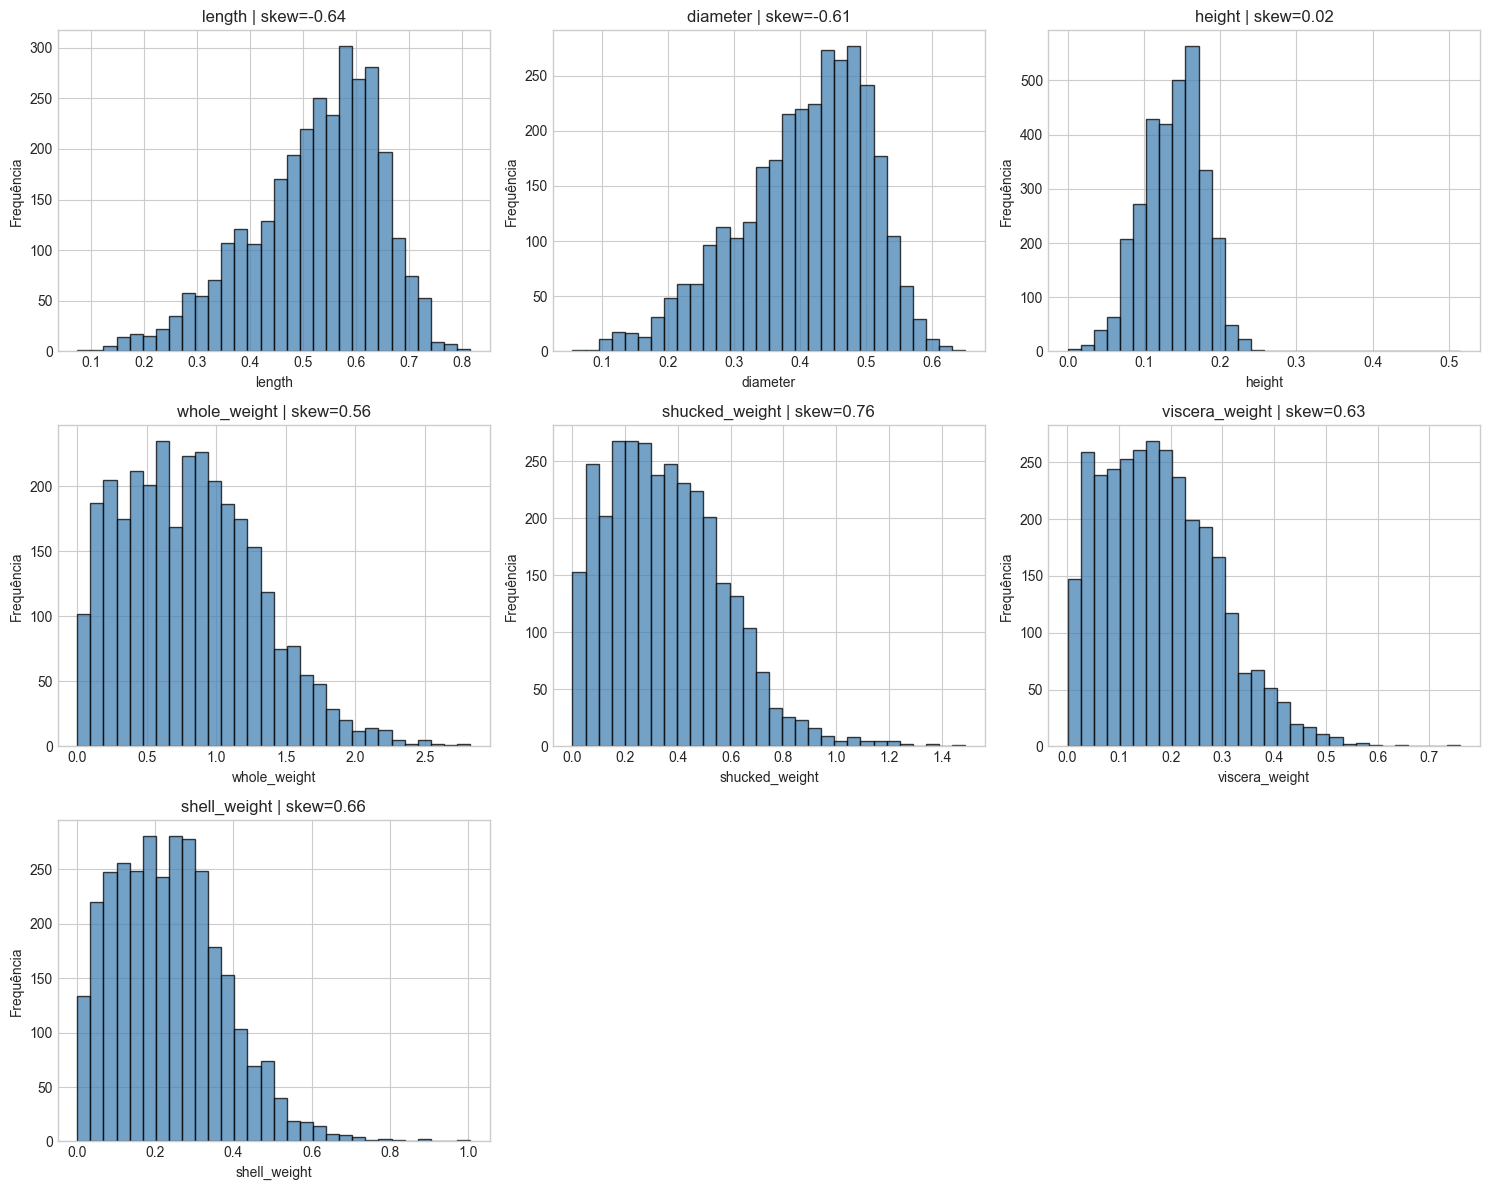

           coluna   skew
0          length -0.637
1        diameter -0.610
2          height  0.020
3    whole_weight  0.557
4  shucked_weight  0.760
5  viscera_weight  0.630
6    shell_weight  0.659


In [12]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

skew_rows = []
for i, col in enumerate(num_cols):
    skew = df[col].skew()
    skew_rows.append((col, skew))
    axes[i].hist(df[col], bins=30, edgecolor='black', alpha=0.75, color='steelblue')
    axes[i].set_title(f'{col} | skew={skew:.2f}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequência')

for j in range(len(num_cols), len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

skew_df = pd.DataFrame(skew_rows, columns=['coluna', 'skew'])
print(skew_df.round(3))


## 2. Boxplots por Classe

Comparando a distribuição de cada variável numérica entre as classes.


/tmp/ipykernel_151195/4262317036.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='type', y=col, ax=axes[i], palette='Set2')
/tmp/ipykernel_151195/4262317036.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='type', y=col, ax=axes[i], palette='Set2')
/tmp/ipykernel_151195/4262317036.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='type', y=col, ax=axes[i], palette='Set2')
/tmp/ipykernel_151195/4262317036.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be remove

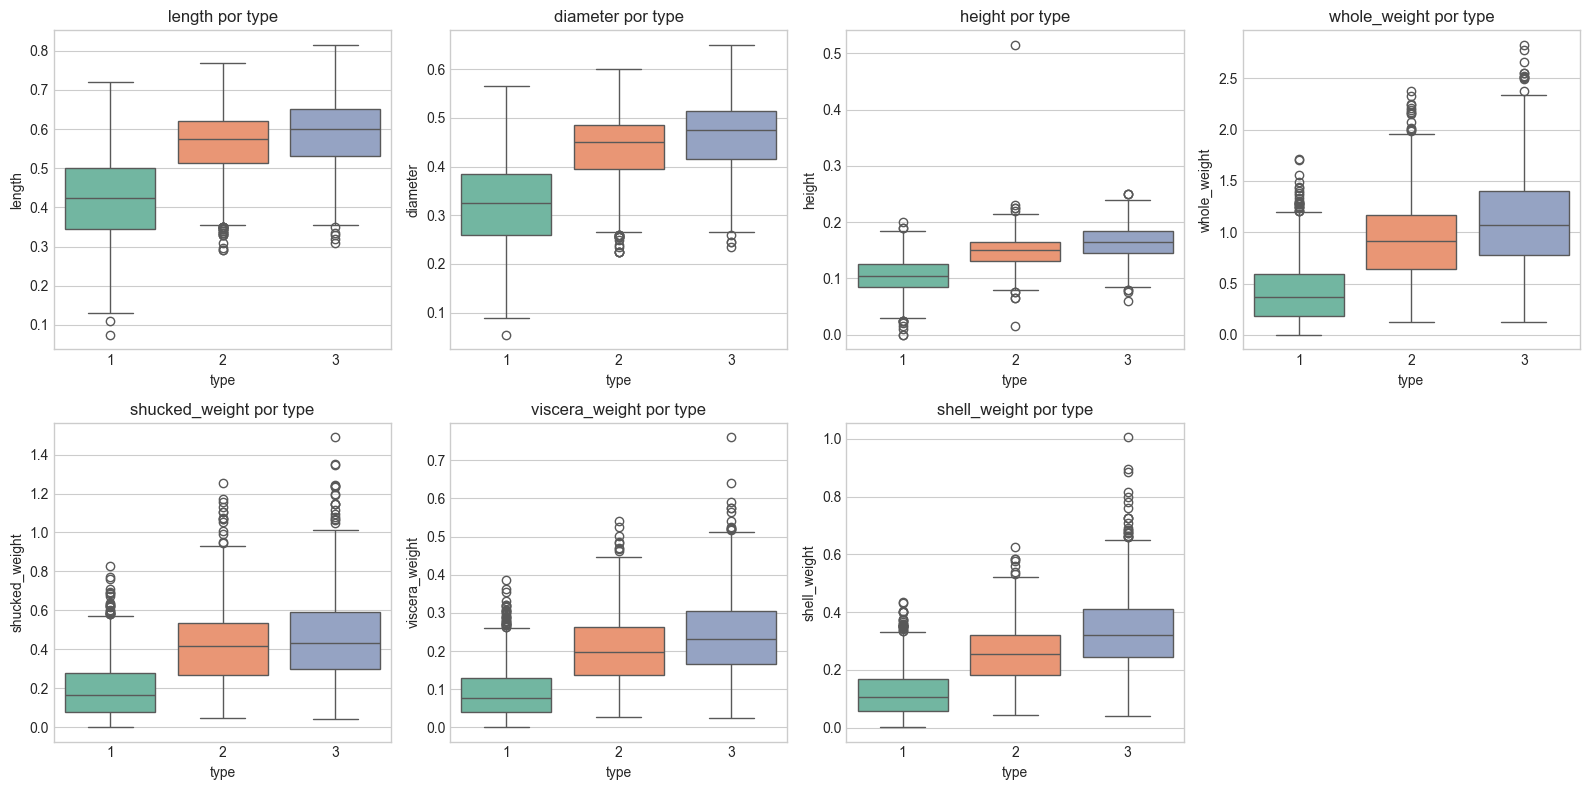

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(data=df, x='type', y=col, ax=axes[i], palette='Set2')
    axes[i].set_title(f'{col} por type')
    axes[i].set_xlabel('type')

axes[-1].axis('off')
plt.tight_layout()
plt.show()


## 3. Outliers via IQR

Identificando valores extremos por regra do IQR.


        coluna  outliers  lower  upper
        length        47  0.210  0.850
      diameter        36  0.142  0.682
        height        14  0.027  0.248
  whole_weight        26 -0.621  2.199
shucked_weight        36 -0.292  0.972
viscera_weight        21 -0.148  0.489
  shell_weight        34 -0.167  0.618


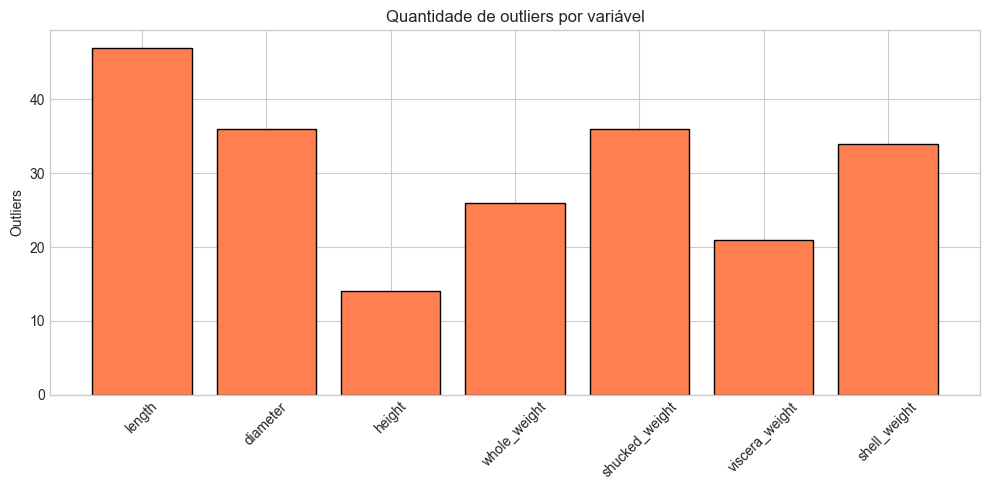

In [14]:
def iqr_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (series < lower) | (series > upper)
    return mask.sum(), lower, upper

rows = []
for col in num_cols:
    n_out, lower, upper = iqr_outliers(df[col])
    rows.append({'coluna': col, 'outliers': n_out, 'lower': lower, 'upper': upper})

outlier_df = pd.DataFrame(rows)
print(outlier_df.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(outlier_df['coluna'], outlier_df['outliers'], color='coral', edgecolor='black')
ax.set_title('Quantidade de outliers por variável')
ax.set_ylabel('Outliers')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 4. Correlações

Avaliando dependências lineares entre as variáveis.


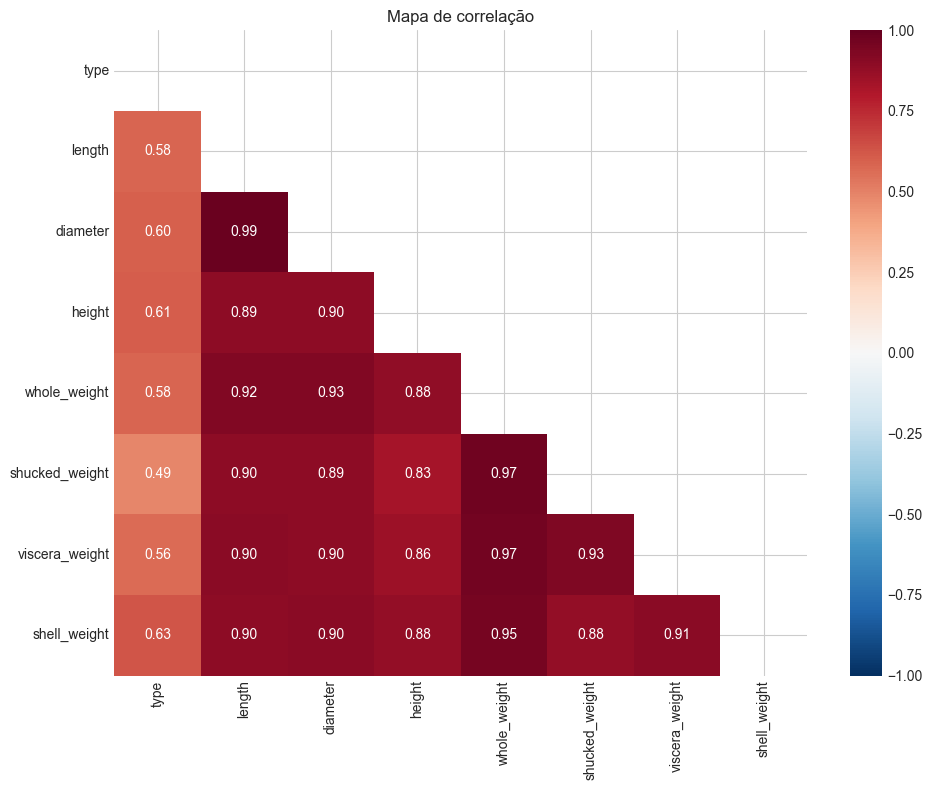

--- Correlação com type ---
shell_weight      0.630
height            0.608
diameter          0.598
length            0.582
whole_weight      0.581
viscera_weight    0.564
shucked_weight    0.491
Name: type, dtype: float64


In [15]:
corr = df[['type'] + num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1)
plt.title('Mapa de correlação')
plt.tight_layout()
plt.show()

print('--- Correlação com type ---')
print(corr['type'].drop('type').sort_values(ascending=False).round(3))


## 5. Relação entre `sex` e `type`

Verificando como a variável categórica se distribui em relação à classe.


type    1    2    3
sex                
F     138  344  471
I     717  214  111
M     223  445  469

Proporção por linha:
type      1      2      3
sex                      
F     0.145  0.361  0.494
I     0.688  0.205  0.107
M     0.196  0.391  0.412


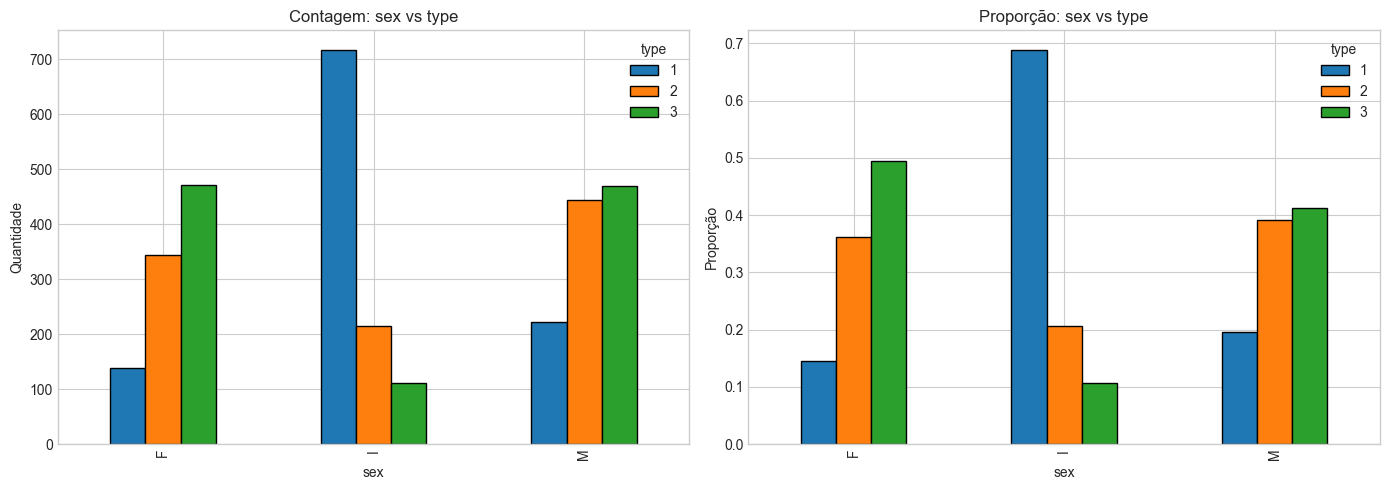

In [16]:
ctab = pd.crosstab(df['sex'], df['type'])
print(ctab)
print('\nProporção por linha:')
print(pd.crosstab(df['sex'], df['type'], normalize='index').round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ctab.plot(kind='bar', ax=axes[0], edgecolor='black')
axes[0].set_title('Contagem: sex vs type')
axes[0].set_xlabel('sex')
axes[0].set_ylabel('Quantidade')

pd.crosstab(df['sex'], df['type'], normalize='index').plot(kind='bar', ax=axes[1], edgecolor='black')
axes[1].set_title('Proporção: sex vs type')
axes[1].set_xlabel('sex')
axes[1].set_ylabel('Proporção')
plt.tight_layout()
plt.show()


## 6. Pairplot em Amostra

Visualização pesada, então usamos uma amostra pequena.


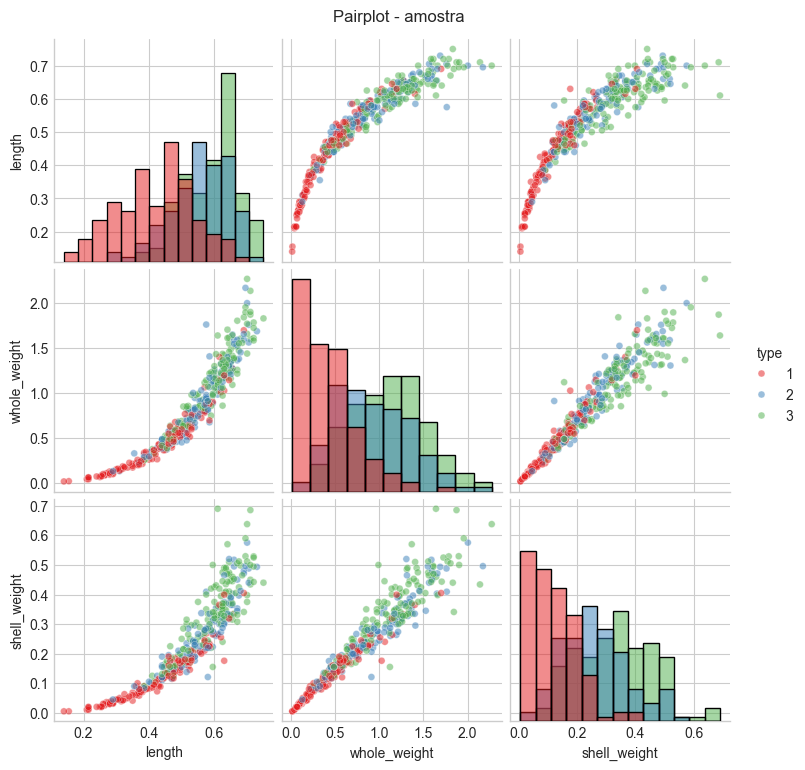

In [17]:
sample_size = 400
sample = df.sample(n=sample_size, random_state=42) if len(df) > sample_size else df.copy()

sns.pairplot(
sample[['length', 'whole_weight', 'shell_weight', 'type']],
hue='type',
palette='Set1',
diag_kind='hist',
plot_kws={'alpha': 0.5, 's': 25}
)
plt.suptitle('Pairplot - amostra', y=1.02)
plt.show()


## 7. Separabilidade via LDA

Projetando as classes em 2 dimensões para ver sobreposição.


Variância explicada: [0.884 0.116]


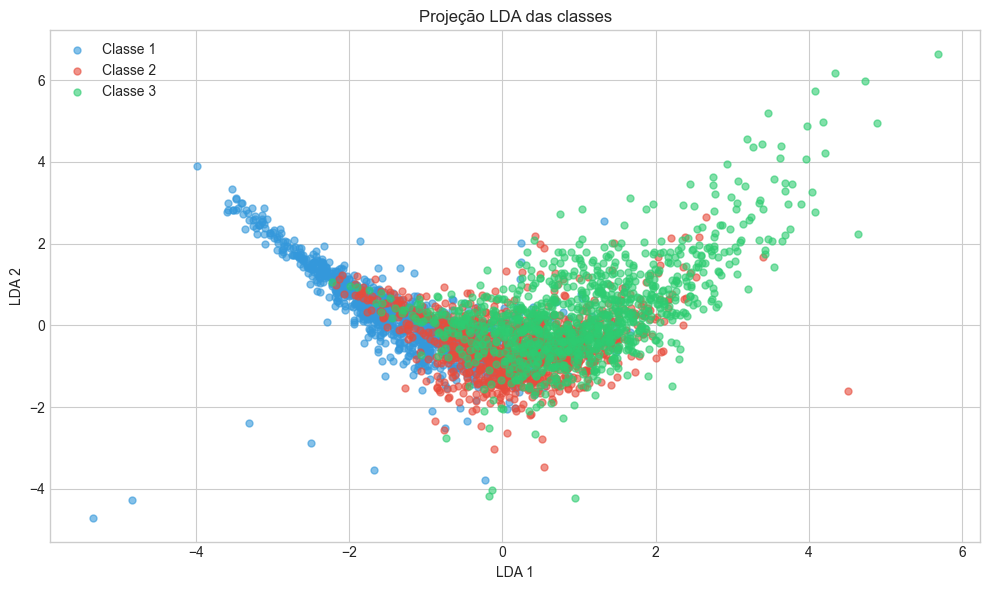

In [18]:
X = StandardScaler().fit_transform(df[num_cols])
y = df['type']

lda = LinearDiscriminantAnalysis(n_components=2)
X_lda = lda.fit_transform(X, y)

print('Variância explicada:', lda.explained_variance_ratio_.round(3))

fig, ax = plt.subplots(figsize=(10, 6))
colors = {1: '#3498db', 2: '#e74c3c', 3: '#2ecc71'}
labels = {1: 'Classe 1', 2: 'Classe 2', 3: 'Classe 3'}
for cls in [1, 2, 3]:
    mask = y == cls
    ax.scatter(X_lda[mask, 0], X_lda[mask, 1],
               s=25, alpha=0.6, c=colors[cls], label=labels[cls])

ax.set_xlabel('LDA 1')
ax.set_ylabel('LDA 2')
ax.set_title('Projeção LDA das classes')
ax.legend()
plt.tight_layout()
plt.show()


## 8. Resumo da EDA

Preencha os pontos abaixo depois de revisar os gráficos.

- [ ] Quais variáveis são mais assimétricas?
- [ ] Quais têm mais outliers?
- [ ] Há correlação alta entre features?
- [ ] `sex` ajuda a separar as classes?
- [ ] A separabilidade sugere modelos simples ou complexos?


In [19]:
print('=' * 60)
print('RESUMO DA EDA')
print('=' * 60)
print('Assimetria por variável:')
for col in num_cols:
    print(f'  {col:20s}: {df[col].skew():.3f}')
print('\nPróximo passo: Notebook 03 - Pré-processamento e transformação')
print('=' * 60)


RESUMO DA EDA
Assimetria por variável:
  length              : -0.637
  diameter            : -0.610
  height              : 0.020
  whole_weight        : 0.557
  shucked_weight      : 0.760
  viscera_weight      : 0.630
  shell_weight        : 0.659

Próximo passo: Notebook 03 - Pré-processamento e transformação
